# Incertidumbre de cotización: opciones SPY

## Decisión
¿Cómo varía el rango bid–ask por vencimiento y cercanía al precio del subyacente? Esta aplicación permite priorizar contratos para revisión de precios y comparar el ancho de cotización. El bid–ask es un rango observado de cotización, **no** un intervalo estadístico ni una banda completa de incertidumbre del modelo.

## Fuente, universo y supuestos
La [cadena diferida Cboe](https://www.cboe.com/delayed_quotes/spy/quote_table) se captura usando el [companion del repositorio](../../../../04-quant-strategy-and-products/derivatives-and-pricing/02-superficie-de-volatilidad-sin-arbitraje/observed_options/README.md). El filtro inicial requiere bid positivo, ask ≥ bid, IV positiva y vencimiento posterior al corte. La fuente se actualiza, de modo que otra ejecución puede generar otro resultado. Si falla la descarga se usa una captura local anterior solo cuando exista, identificada por su fecha; este archivo no se distribuye y no está garantizado en una copia nueva. El archivo bruto no se redistribuye; el manifiesto registra hash y hora. Las opciones SPY son americanas, con dividendos; no se asume una fórmula europea. Cotizaciones diferidas pueden estar desactualizadas o no ejecutarse. [Cboe](https://optionsfacts.cboe.com/) describe el diferencial bid–ask como una dimensión de liquidez.

In [1]:
from pathlib import Path
import pandas as pd, numpy as np, matplotlib.pyplot as plt, hashlib
root=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'03-financial-risk').is_dir())
plt.rcParams.update({'figure.figsize':(10,4),'axes.grid':True})

## Descarga y controles
Se utiliza la extracción existente del repositorio, sin modificarla. Se registran filas, fecha informada por el proveedor y huella de la respuesta; la hora de mercado no tiene zona horaria documentada en esta fuente.

In [2]:
import subprocess,sys,json
folder=root/'04-quant-strategy-and-products/derivatives-and-pricing/02-superficie-de-volatilidad-sin-arbitraje/observed_options'
capture=subprocess.run([sys.executable,str(folder/'download.py')],capture_output=True,text=True)
if capture.returncode != 0:
 print('Descarga no disponible; se usa la captura local anterior si existe. No se garantiza vigencia.')
 if not (folder/'output/manifest.json').exists(): raise RuntimeError('Ejecute download.py cuando la fuente publique cotizaciones válidas; no hay captura local.')
manifest=json.loads((folder/'output/manifest.json').read_text()); df=pd.read_csv(folder/'output/spy_quotes.csv',parse_dates=['expiry'])
asof=pd.Timestamp(manifest['source_timestamp'][:10]); df['dias']=(df.expiry-asof).dt.days
assert df.contract.is_unique and (df.bid>0).all() and (df.ask>=df.bid).all() and (df.dias>0).all()
df['medio']=(df.bid+df.ask)/2; df['spread']=df.ask-df.bid; df['spread_relativo']=df.spread/df.medio
print('Filas:',len(df),'| Corte:',manifest['source_timestamp'],'| SHA-256 respuesta:',manifest['raw_sha256'])
print('Tipos:',df.type.value_counts().to_dict(),'| bid=ask:',int((df.spread==0).sum()))
df[['contract','expiry','strike','bid','ask','spread_relativo']].head()

Filas: 10786 | Corte: 2026-11-12 14:45:12 | SHA-256 respuesta: 7fee5a37df4c934910df38649a4cbcaba166d77aca5a0ed09339dd94b2751a6e
Tipos: {'C': 5713, 'P': 5073} | bid=ask: 5


,contract,expiry,strike,bid,ask,spread_relativo
0,SPY261113C00505000,2026-11-13,505.0,247.87,251.26,0.013584
1,SPY261113C00510000,2026-11-13,510.0,242.93,246.26,0.013614
2,SPY261113C00515000,2026-11-13,515.0,237.87,241.26,0.014151
3,SPY261113C00520000,2026-11-13,520.0,232.87,236.27,0.014495
4,SPY261113C00525000,2026-11-13,525.0,227.87,231.27,0.014810


## Medición por región de mercado
Comparamos dos grupos de strike sobre spot (0,95–1,05 y fuera de ese rango) y plazos 1–30, 31–90 y >90 días. Usamos mediana y percentiles del spread relativo para evitar que unos pocos contratos dominen el resumen. Son umbrales de segmentación descriptivos, no reglas de calidad aprobadas.

In [3]:
df['moneyness']=np.where(df.strike_over_spot.between(0.95,1.05),'Cerca del spot','Resto')
df['plazo']=pd.cut(df.dias,[0,30,90,np.inf],labels=['1–30','31–90','>90'])
res=df.groupby(['type','moneyness','plazo'],observed=True).spread_relativo.agg(n='size',mediana='median',p25=lambda x:x.quantile(.25),p75=lambda x:x.quantile(.75))
res.round(4)

n  mediana     p25     p75
type moneyness      plazo                               
C    Cerca del spot 1–30    932   0.0240  0.0135  0.0708
                    31–90   301   0.0365  0.0198  0.1054
                    >90     448   0.0616  0.0141  0.0803
     Resto          1–30    967   0.0420  0.0225  0.1072
                    31–90   811   0.0384  0.0195  0.0718
                    >90    2254   0.0265  0.0154  0.0535
P    Cerca del spot 1–30    787   0.0247  0.0191  0.0345
                    31–90   301   0.0199  0.0132  0.1091
                    >90     448   0.0112  0.0101  0.0123
     Resto          1–30    686   0.0488  0.0317  0.0952
                    31–90   535   0.0232  0.0154  0.0625
                    >90    2316   0.0166  0.0124  0.0328

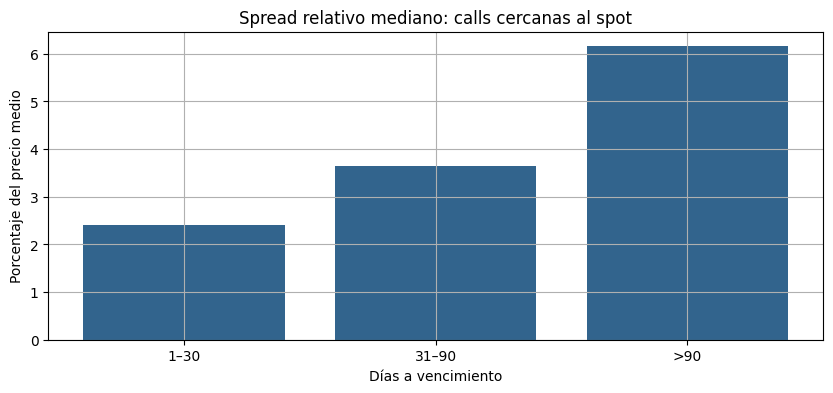

In [4]:
subset=res.reset_index(); sub=subset[(subset.type=='C')&(subset.moneyness=='Cerca del spot')]
fig,ax=plt.subplots();ax.bar(sub.plazo.astype(str),100*sub.mediana,color='#32648d');ax.set(title='Spread relativo mediano: calls cercanas al spot',xlabel='Días a vencimiento',ylabel='Porcentaje del precio medio');plt.show()

## Ejemplo revisable de contrato
Seleccionamos la call más cercana al spot entre contratos con plazo 31–90 días; es una selección mecánica, no una recomendación. El rango bid–ask se refiere a esa cotización y no incluye incertidumbre de modelo, costos o riesgo de ejecución.

In [5]:
candidatos=df[(df.type=='C') & df.dias.between(31,90)].copy()
if candidatos.empty: print('Sin contratos admisibles en esta captura')
else:
 candidatos['distancia']=(candidatos.strike_over_spot-1).abs()
 elegido=candidatos.sort_values(['distancia','dias','contract']).iloc[0]
 print('Contrato:',elegido.contract,'| Días:',elegido.dias,'| Bid/ask USD:',elegido.bid,elegido.ask,'| Spread %:',round(100*elegido.spread_relativo,2))

Contrato: SPY261218C00754000 | Días: 36 | Bid/ask USD: 15.5 15.8 | Spread %: 1.92


## Interpretación y siguientes controles
La comparación es transversal y depende de una sola captura. Ni volumen ni open interest aseguran ejecución; una calibración de modelo requiere series con calidad, convenciones, dividendos y tasas, además de evaluación fuera de muestra. No convertir estas bandas de cotización en una estimación probabilística de valor justo.